# Phase 5: Frequency Model, GAM and Benchmark vs. the GLM

**Business question this phase serves:** *do smooth, non-linear effects improve on the Phase 4 GLM's
straight-line terms, by how much, and is the gain worth the loss of interpretability?* Phase 4 flagged
two factors whose shape a linear term cannot follow: `DrivAge` (sharp young-driver drop, then roughly
flat) and `VehAge` (a hump, not a straight decline).

**Inputs:** [`data/processed/train.parquet`](../data/processed/train.parquet),
[`val.parquet`](../data/processed/val.parquet), and
[`models/freq_glm.pkl`](../models/freq_glm.pkl) (Phase 4's fitted GLM, reused as is).

**What this notebook does:**
1. Build GAM-specific features (a GAM needs a different representation from the GLM's one-hot matrix).
2. Fit a Poisson GAM on a stratified sub-sample, for the same memory reasons as Phase 4.
3. Show why comparing the GAM's in-sample fit with the GLM's is misleading.
4. Compare both models on the same validation set: deviance, Gini/Lorenz curve, actual vs. predicted
   by decile.
5. Partial dependence curves for `DrivAge` and `VehAge`.
6. The accuracy vs. interpretability trade-off.

## 0. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

# pygam's IRLS loop emits benign runtime warnings (divide-by-zero encountered while evaluating a
# candidate step that gets rejected) that are noisy but not actionable: suppressed here, the way a
# production notebook would, rather than left to clutter every output cell.
warnings.filterwarnings("ignore")


def find_project_root(marker: str = "requirements.txt") -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f"Could not locate project root (looked for '{marker}' upward from {here})")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.features.pipeline import get_exposure_offset, get_frequency_target
from src.models.frequency_gam import GAMFeatureBuilder, fit_poisson_gam, ALL_GAM_COLS
from src.models.glm_diagnostics import (
    actual_vs_predicted_by_decile,
    out_of_sample_pseudo_r2,
    plot_actual_vs_predicted,
    poisson_deviance,
)
from src.models.model_comparison import gini_coefficient, lorenz_curve_data, plot_lorenz_curves

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

train_df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "train.parquet")
val_df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "val.parquet")
encoder = joblib.load(PROJECT_ROOT / "models" / "feature_encoder.joblib")
freq_glm = joblib.load(PROJECT_ROOT / "models" / "freq_glm.pkl")  # Phase 4's fitted GLM: reused, not refit

print(f"Train: {len(train_df):,} rows | Validation: {len(val_df):,} rows")
print(f"GLM loaded: {len(freq_glm['feature_columns'])} feature columns")

Train: 401,175 rows | Validation: 133,725 rows
GLM loaded: 37 feature columns


## 1. GAM-specific feature preparation

`src/features/pipeline.py`'s `PolicyFeatureEncoder` (Phase 3) one-hot-encodes categorical factors,
which is what a GLM's linear predictor needs. A GAM works differently: `pygam` fits a smooth spline
`s()` to each continuous factor and a per-level step function `f()` to each categorical factor
*natively*: one-hot dummies would force it to fit a disconnected mini-model to each 0/1 indicator
instead. So this phase uses `GAMFeatureBuilder` (`src/models/frequency_gam.py`), a parallel encoder
that reuses Phase 3's *decisions* (which factors, `Area` excluded, `log(Density)`) but not its literal
output format: importantly, it reuses Phase 3's exact `VehAge` capping threshold (99.5th percentile
of train, `24.0` years) rather than recomputing its own, so the GLM and GAM never silently disagree on
a data-preparation choice that isn't actually part of what's being compared.

In [2]:
gam_builder = GAMFeatureBuilder().fit(train_df, vehage_cap=encoder.vehage_cap_)
print(f"GAM feature columns (in order): {ALL_GAM_COLS}")
print(f"VehAge cap reused from Phase 3: {gam_builder.vehage_cap_}")

GAM feature columns (in order): ['DrivAge', 'BonusMalus', 'VehPower', 'log_Density', 'VehAge_capped', 'VehBrand', 'VehGas', 'Region']
VehAge cap reused from Phase 3: 24.0


## 2. Fitting: a memory-aware fallback strategy

A Poisson GAM with 5 spline terms and 3 factor terms is heavier than the GLM (each spline expands into
several basis columns). On this 8GB-RAM machine the same fit can succeed or run out of memory depending
on what else is running, so `src/models/frequency_gam.py` provides `fit_poisson_gam_with_fallback`: it
tries configurations from the largest (25% of train, 10 spline knots per term) down to the smallest (3%,
5 knots), moving to the next one on a `MemoryError`. The configuration actually used is printed below.

**Smoothing:** `pygam`'s automatic smoothing search (`gam.gridsearch`) did not converge on this term
specification, so the default smoothing (`lam=0.6`) is used for every term. A documented
simplification.

In [3]:
import time
from src.models.frequency_gam import fit_poisson_gam_with_fallback

t0 = time.time()
gam, gam_config = fit_poisson_gam_with_fallback(train_df, gam_builder, verbose=True)
print(f"\nTotal fit time (including any fallback retries): {time.time() - t0:.1f}s")
print(f"Configuration used: {gam_config['train_size']:.0%} of train ({gam_config['n_rows']:,} rows), "
      f"n_splines={gam_config['n_splines']}")
print(f"Terms: {[str(t) for t in gam.terms]}")

GAM fit succeeded: train_size=25% (100,293 rows), n_splines=10

Total fit time (including any fallback retries): 51.2s
Configuration used: 25% of train (100,293 rows), n_splines=10
Terms: ['spline_term', 'spline_term', 'spline_term', 'spline_term', 'spline_term', 'factor_term', 'factor_term', 'factor_term', 'intercept_term']


## 3. Why the in-sample comparison is misleading

`pygam` reports its own in-sample pseudo-R². Comparing it directly with the GLM's in-sample figure
(4.1%, Phase 4) would be a mistake, for the reasons below.

In [4]:
gam_insample_r2 = gam.statistics_["pseudo_r2"]["explained_deviance"]
glm_res = freq_glm["results"]
glm_insample_r2 = 1 - glm_res.deviance / glm_res.null_deviance
naive_ratio = gam_insample_r2 / glm_insample_r2
print(f"GAM in-sample pseudo-R^2 (pygam's own statistic): {gam_insample_r2:.4f}  ({gam_insample_r2:.1%})")
print(f"GLM in-sample pseudo-R^2 (Phase 4, full training set): {glm_insample_r2:.4f}  ({glm_insample_r2:.1%})")
print(f"\nNaive read: the GAM looks {naive_ratio:.1f}x better. This is NOT a trustworthy comparison.")

GAM in-sample pseudo-R^2 (pygam's own statistic): 0.1002  (10.0%)
GLM in-sample pseudo-R^2 (Phase 4, full training set): 0.0406  (4.1%)

Naive read: the GAM looks 2.5x better. This is NOT a trustworthy comparison.


**Why this comparison does not hold:**
1. **Different training sets.** The GLM was fitted on all 401,175 training rows, the GAM on a 25%
   sub-sample. In-sample statistics are not comparable across sample sizes.
2. **In-sample fit rewards flexibility.** A GAM with fairly flexible splines (`lam=0.6`) will always
   fit its own training data better than a linear GLM; that says nothing yet about whether it captures
   signal or noise.

The fair comparison scores both models on data neither was fitted on: the validation set, next.

## 4. Out-of-sample comparison on the validation set

In [5]:
# --- GLM predictions on validation (Phase 4's fitted model, no refit) ---
X_val_glm = encoder.transform(val_df)
X_val_glm_const = sm.add_constant(X_val_glm[freq_glm["feature_columns"]], has_constant="add")
offset_val = get_exposure_offset(val_df)
pred_glm_val = freq_glm["results"].predict(X_val_glm_const, offset=offset_val)

# --- GAM predictions on validation ---
X_val_gam = gam_builder.transform(val_df)
exposure_val = val_df["Exposure"].to_numpy(dtype=float)
pred_gam_val = gam.predict(X_val_gam, exposure=exposure_val)

y_val = get_frequency_target(val_df).to_numpy(dtype=float)

# --- Out-of-sample deviance & pseudo-R^2, computed identically for both models ---
glm_r2 = out_of_sample_pseudo_r2(y_val, pred_glm_val, exposure_val)
gam_r2 = out_of_sample_pseudo_r2(y_val, pred_gam_val, exposure_val)

print(f"{'Metric':<32}{'GLM':>12}{'GAM':>12}")
print(f"{'Validation deviance':<32}{glm_r2['model_deviance']:>12,.1f}{gam_r2['model_deviance']:>12,.1f}")
print(f"{'Validation pseudo-R^2':<32}{glm_r2['pseudo_r2']:>11.2%} {gam_r2['pseudo_r2']:>11.2%}")

Metric                                   GLM         GAM
Validation deviance                 32,563.2    32,235.8
Validation pseudo-R^2                 4.53%       5.49%


**Finding:** on the validation set the GAM's pseudo-R² (5.49%) is higher than the GLM's (4.53%) and
its deviance is lower. A real improvement, but a modest one, far from the 2.5x suggested by the
in-sample comparison.

Gini (GLM): 0.2852
Gini (GAM): 0.3105


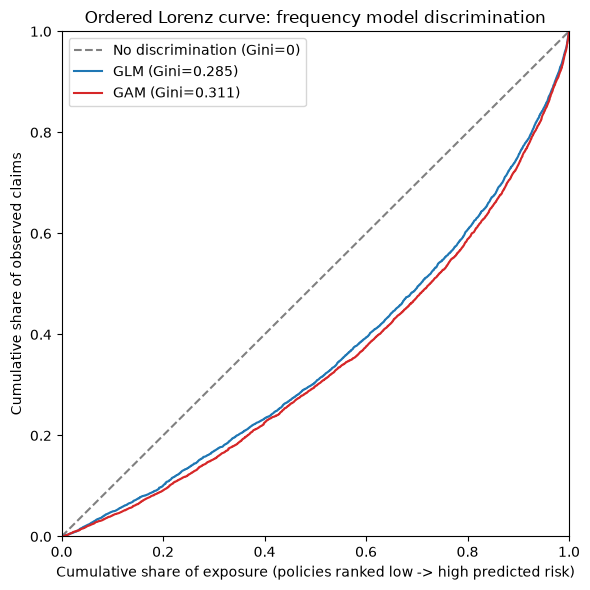

In [6]:
# --- Gini / Lorenz curve, both models, validation set ---
lorenz_glm = lorenz_curve_data(y_val, pred_glm_val, exposure_val)
lorenz_gam = lorenz_curve_data(y_val, pred_gam_val, exposure_val)
gini_glm = gini_coefficient(lorenz_glm)
gini_gam = gini_coefficient(lorenz_gam)

print(f"Gini (GLM): {gini_glm:.4f}")
print(f"Gini (GAM): {gini_gam:.4f}")

fig = plot_lorenz_curves({"GLM": lorenz_glm, "GAM": lorenz_gam}, {"GLM": gini_glm, "GAM": gini_gam})
plt.show()

**Reading:** the GAM's Lorenz curve bows further from the diagonal and its Gini (0.311) is higher
than the GLM's (0.285): the GAM ranks policies by risk somewhat better, consistent with the pseudo-R²
gap.

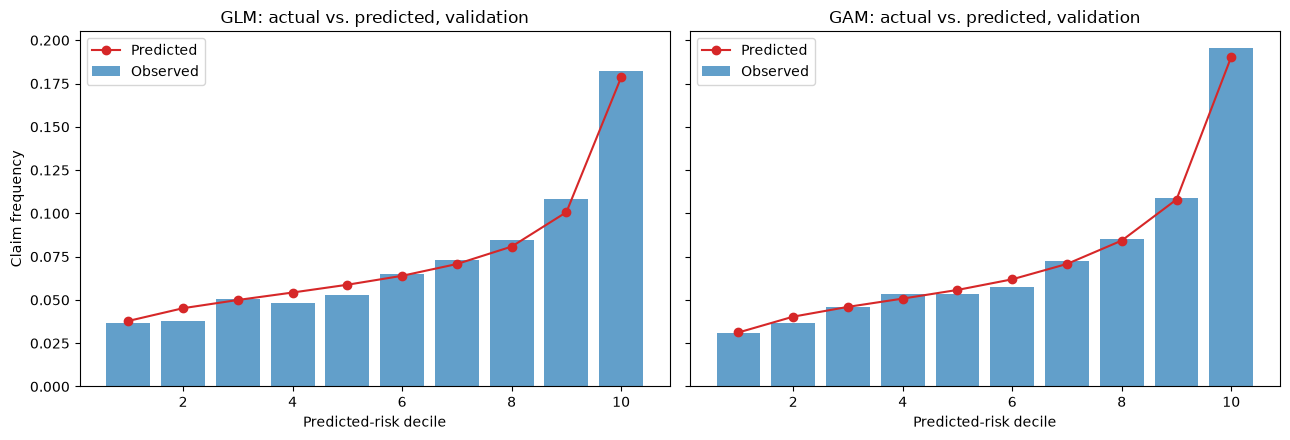

In [7]:
decile_glm = actual_vs_predicted_by_decile(y_val, pred_glm_val, exposure_val, n_bins=10)
decile_gam = actual_vs_predicted_by_decile(y_val, pred_gam_val, exposure_val, n_bins=10)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, decile_df, name in [(ax1, decile_glm, "GLM"), (ax2, decile_gam, "GAM")]:
    ax.bar(decile_df["bin"], decile_df["observed_frequency"], color="#1f77b4", alpha=0.7, label="Observed")
    ax.plot(decile_df["bin"], decile_df["predicted_frequency"], color="#d62728", marker="o", label="Predicted")
    ax.set_title(f"{name}: actual vs. predicted, validation")
    ax.set_xlabel("Predicted-risk decile")
    ax.legend()
ax1.set_ylabel("Claim frequency")
fig.tight_layout()
plt.show()

**Reading:** both models track observed frequency across the 10 deciles; neither is badly
miscalibrated. The difference is hard to see at this resolution; the shapes the GAM learned, next, are
more informative.

## 5. Partial dependence: what did the GAM learn?

In Phase 4, `DrivAge`'s multivariate GLM coefficient was a single slope (+0.0058 per year) and so was
`VehAge`'s (-0.018 per year). A GAM smooth term shows the whole shape instead, plotted here on the
relativity scale (exp of the centered partial effect), next to the GLM's line.

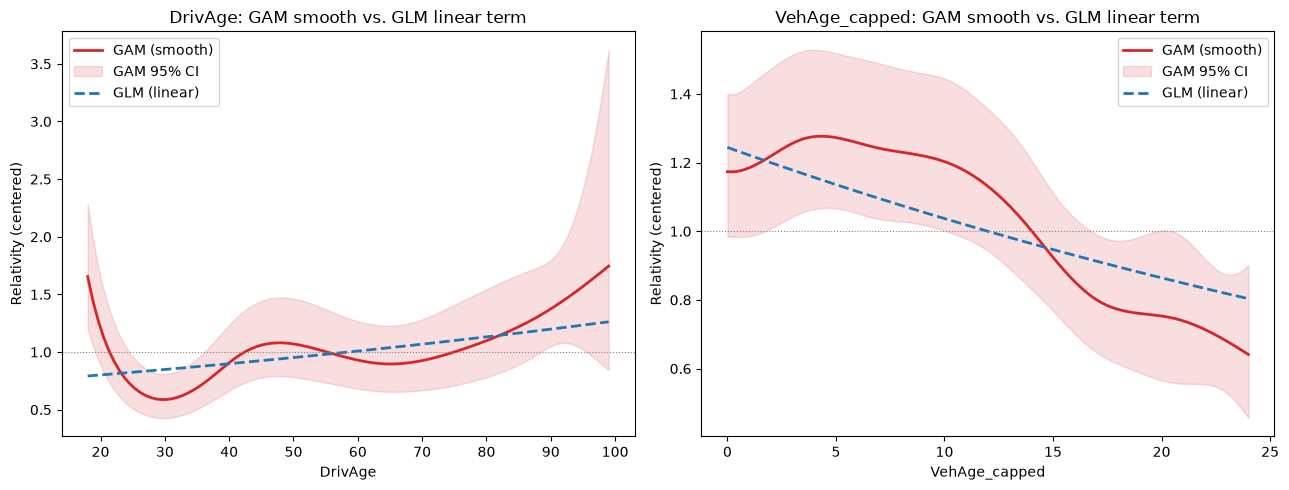

In [8]:
def plot_partial_dependence(gam, term_index, feature_name, glm_coefficient, ax):
    XX = gam.generate_X_grid(term=term_index, n=100)
    pdep, confi = gam.partial_dependence(term=term_index, X=XX, width=0.95)
    x_vals = XX[:, term_index]

    # Center the GAM curve and the GLM line at the same point (the mean of the grid) so the two
    # are visually comparable on the same relativity scale: otherwise their arbitrary baselines
    # would make a side-by-side comparison meaningless.
    gam_relativity = np.exp(pdep - pdep.mean())
    ci_lower = np.exp(confi[:, 0] - pdep.mean())
    ci_upper = np.exp(confi[:, 1] - pdep.mean())

    glm_linear_effect = glm_coefficient * x_vals
    glm_relativity = np.exp(glm_linear_effect - glm_linear_effect.mean())

    ax.plot(x_vals, gam_relativity, color="#d62728", linewidth=2, label="GAM (smooth)")
    ax.fill_between(x_vals, ci_lower, ci_upper, color="#d62728", alpha=0.15, label="GAM 95% CI")
    ax.plot(x_vals, glm_relativity, color="#1f77b4", linewidth=2, linestyle="--", label="GLM (linear)")
    ax.axhline(1.0, color="gray", linewidth=0.8, linestyle=":")
    ax.set_xlabel(feature_name)
    ax.set_ylabel("Relativity (centered)")
    ax.set_title(f"{feature_name}: GAM smooth vs. GLM linear term")
    ax.legend()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
plot_partial_dependence(gam, 0, "DrivAge", freq_glm["results"].params["DrivAge"], ax1)
plot_partial_dependence(gam, 4, "VehAge_capped", freq_glm["results"].params["VehAge_capped"], ax2)
fig.tight_layout()
plt.show()

**`DrivAge`:** the curve is high at 18 (relativity about 1.66), falls to a minimum around age 30
(about 0.59), rises to about 1.07 at 45-50, dips to about 0.90 around 65, then rises again after 75
(1.10 at 80, 1.22 at 85). This is a multivariate curve with `BonusMalus` held fixed, which is why the
young-driver effect is smaller than Phase 2's univariate 19.3% (the confounding Phase 4 found). The
95% band widens sharply beyond 85, where data are thin: that tail is not read as a finding. The GLM's
straight line, nearly flat, captures none of this.

**`VehAge`:** a plateau from new vehicles to about 10 years (relativity 1.17 to 1.27, highest around
4-5 years), then a steady decline to about 0.64 at the 24-year cap. A single downward slope (the GLM)
understates the plateau and overstates the decline for young vehicles.

Both shapes are used in Phase 7 to define bins for an improved GLM.

## 6. GLM vs. GAM: the trade-off

| | GLM (Phase 4) | GAM (this phase) |
|---|---|---|
| Validation pseudo-R² | 4.53% | 5.49% |
| Validation Gini | 0.285 | 0.311 |
| Follows `DrivAge`'s shape (young-driver drop, mid-life rise, rise after 75) | No, one straight line | Yes |
| Follows `VehAge`'s plateau then decline | No, one straight line | Yes |
| Output | A table of coefficients, directly usable as a rate table | A set of curves, to be binned before use in a rate table |
| Training on this machine | Seconds, full 401,175-row training set | About 55s on a 25% sub-sample (100,293 rows) |
| Statistical inference | Standard (Wald and LR tests) | `pygam`'s p-values carry a library-documented caveat |

**Conclusion:** the GAM captures more structure and validates better out of sample. A GLM, however,
reads directly as a rate table and is simpler to explain and to file; a GAM's curves would need to be
discretized first, giving back part of the gain. The practical route: use the GAM's curves (Section 5)
to re-bin `DrivAge` and `VehAge` in an improved GLM, which is what Phase 7 does.

## 7. Save the GAM

In [9]:
models_dir = PROJECT_ROOT / "models"
joblib.dump({"gam": gam, "feature_builder": gam_builder}, models_dir / "freq_gam.pkl")
print(f"Saved: {(models_dir / 'freq_gam.pkl').relative_to(PROJECT_ROOT).as_posix()}")

Saved: models/freq_gam.pkl


## Phase 5 summary

| Check | Result |
|---|---|
| GAM fitting strategy | Memory-aware fallback; this run used the largest configuration (25% of train, 100,293 rows, 10 knots per term) |
| In-sample GAM vs. GLM comparison | Shown to be misleading (different training sizes, in-sample rewards flexibility), not used |
| Out-of-sample validation deviance | GLM 32,563 vs. GAM 32,236 |
| Out-of-sample validation pseudo-R² | GLM 4.53% vs. GAM 5.49% |
| Gini (validation) | GLM 0.285 vs. GAM 0.311 |
| `DrivAge` partial dependence | Young-driver effect smaller once `BonusMalus` is held fixed; trough near 30, rise to 45-50, dip near 65, rise after 75 (thin data beyond 85) |
| `VehAge` partial dependence | Plateau up to about 10 years, then decline |
| Trade-off | GAM more accurate, less directly usable as a rate table |

**Next:** Phase 7 uses these curves to define `DrivAge` and `VehAge` bins for a refined GLM.

**Output:** [`models/freq_gam.pkl`](../models/freq_gam.pkl), ready for
**Phase 6: severity model, GLM (Gamma) and GAM**.